scikit-learn.org

## Dimensionalidades
Caracteristicas de los datos que definen esa clase (En el caso del de cancer de mama, 30 dimensiones (textura, perimetro, etc...) que definen 2 clases, maligno y benigno)



In [ ]:
# KNN Classification Example - Breast Cancer Dataset

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import seaborn as sns
import matplotlib.pyplot as plt

## Preparacion de datos
Antes de meter los datos al modelo debo estandarizar los datos, es como una normalizacion en la que el dato se pone a nivel de una escala (Para que todos los datos esten en la misma escala)

Ej: Perimetro de 0-100 y una textura de 0-1, si no se pone en escala el perimetro hara mucho ruido en el modelo

## Parte de entrenamiento
Normalmente teneos 20% para el test y 80% para el modelo y para la parrte de estandarizar la esacala en los imports se usa StandardScale

## Primera seccion
Cargamos el data set como tal y separamos 2 partes, el .data y el .target (x, y)
En x estan los datos numeros de las caracteristicas (30) y en el y tenemos el si es maligno o benigno, es decir el target, objetivo o clase

## Parámetros Generales de la Separación de Datos (train_test_split)
Para entrenar cualquier modelo supervisado, primero debemos segmentar nuestra información en variables predictoras (X) y la variable objetivo (y). A partir de ahí, realizamos la división esencial para el flujo de trabajo:

test_size=0.2 (Tamaño del test): Significa que el 80% de los datos se destina a la Inducción (Entrenamiento) y el 20% restante se guarda exclusivamente para la Deducción (Evaluación). El estándar de usar entre un 20% y un 30% existe para evitar el Overfitting (Sobreajuste); si dejamos muy pocos datos para testear, no podremos medir con certeza la verdadera capacidad de generalización del modelo. Como regla general en Machine Learning: entre más datos de calidad tenga el algoritmo para entrenar, mejor descubrirá el patrón y mejor generalizará ante datos nuevos.

random_state (Control de aleatoriedad): Por defecto, la función selecciona los registros para el train y el test de forma completamente aleatoria. Si ejecutas el código hoy y lo vuelves a ejecutar mañana sin este parámetro, el split cambiará, lo que alterará ligeramente las métricas (como el Accuracy) y hará imposible replicar tus experimentos. Al fijar el random_state, bloqueas esa selección aleatoria: siempre que uses el mismo número, obtendrás exactamente la misma partición de datos.

##¿Qué pasa si se usan otros números en el random_state en lugar de 42?
No cambia la calidad del modelo: El número 42 no tiene ninguna propiedad matemática mágica que mejore el algoritmo (es simplemente un guiño de la cultura geek a la novela Guía del autoestopista galáctico).

Si pones 1, 2, 100 o cualquier otro entero: El código funcionará exactamente igual de bien. Lo único que ocurre es que el algoritmo mezclará y elegirá un grupo de datos diferente para el entrenamiento y la prueba.

El único riesgo de cambiarlo constantemente: Si pruebas tu modelo probando aleatoriamente con random_state=1, luego random_state=2, etc., hasta encontrar el que te dé mayor precisión, estarías cayendo en una mala práctica. Estarías "trampeando" el diseño al elegir la partición que por pura suerte favorece a tu modelo, arruinando la validación real de su capacidad de generalización. Lo correcto es fijar un número (como el estándar 42) y dejarlo quieto mientras evalúas los algoritmos.

# Escalabilida(importante para el KNN)
Generamos una variable scaler y se llama el StandarSDcaler y se aplica en el traint y test de x, NO de y, el fit transformation es para igualar los rangos ya que si no se hace el modelo se puede equivocar por darle mas peso a una columna y los demas datos dejan de tener relevancia, por eso se hace un reescalado, en este caso el scalar.fit resta por la media y divide por la desviacion estandar de los datos.

Re-escalado = x-(xmedia)/desviacion_datos

La diferencia entre fitTransform y transform es que si yo tambien escalo en los valores de test ya el dato no seria el original despues de la estandarizacion


In [ ]:
# 1. Load dataset
data = load_breast_cancer()
X = data.data
y = data.target

# 2. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Feature scaling (important for KNN)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# Para entrenar el KNN
el numero estandar dentro del n_neighbors es =5
En el .fit se asigna los datos de entrenamiento,tanto x como y

Depues se hacen las predicciones con el .predict sobre las etiquetas de test de los dtos (las que no estan estandarizadas)

Al ultimo se llaa el accuracy y que plotee las targets originales y las que el modelo regresa, es decir, test y predicciones

Asi mismo con el reporte de clasificacion al que se le lleva lo mismo  

Depues lo llevo a una matriz de confusion, llevo esas metricas e imprimo


In [ ]:

# 4. Train KNN model
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

# 5. Predictions
y_pred = knn.predict(X_test)

# 6. Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# 7. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

Accuracy: 0.9473684210526315

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.93      0.93        43
           1       0.96      0.96      0.96        71

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



### ¿Cómo interpretar el Classification Report?

* **Precision:** ¿Qué tan acertado es el modelo al etiquetar? (Evita falsas alarmas).
* **Recall:** ¿Qué porcentaje de los casos reales logró capturar el modelo? (Evita que se le escapen enfermos).
* **F1-Score:** El balance perfecto (promedio) entre Precision y Recall.
* **Support:** La cantidad real de muestras evaluadas por cada clase en el set de prueba.

* **Macro Avg:** Promedio simple entre las clases (asume que ambas clases valen lo mismo en peso).
* **Weighted Avg:** Promedio ajustado al volumen de datos (le da más peso a la clase que tiene más muestras).


###*Sobre esta linea actuan el resto de modelos*

#### ¿Como se lee la matriz de confusion?
La matriz de confusion se lee dependiendo en donde se encuentra la exactitud de los datos por ejemplo el modelo puede predecir de manera correcta 40 tuores coo malignos y 3 los ha calificado de manera erronea siendo un falso positivo ientras que en la parte beningna son 68 tuores beningnos y el odelo se equivoco en 3 para calificar coo beningnos siendo estos alignos


#### Extra:
La matriz de confusion en un analisis adicional para saber como funciona el modelo

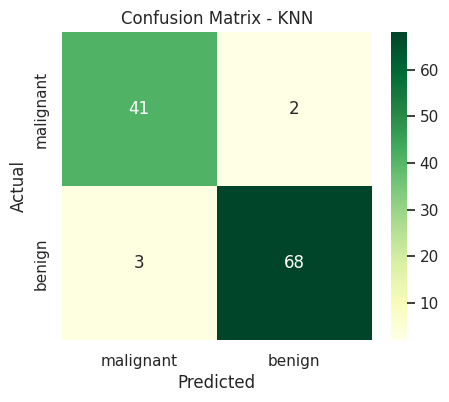

In [ ]:
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="YlGn", # ó Greens
            xticklabels=data.target_names,
            yticklabels=data.target_names)

plt.title("Confusion Matrix - KNN")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Accuracy: 0.956140350877193

Classification Report:

              precision    recall  f1-score   support

           0       0.93      0.95      0.94        43
           1       0.97      0.96      0.96        71

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



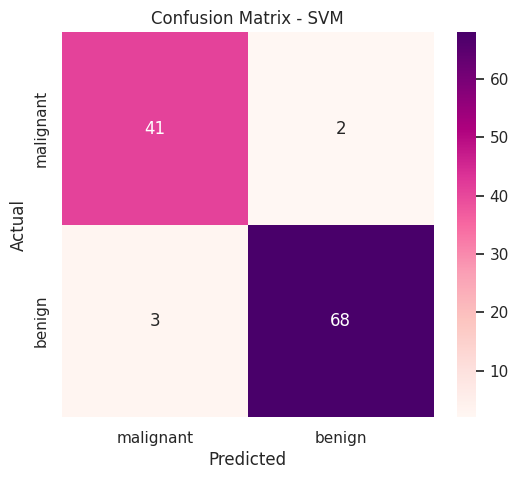

In [ ]:
# =========================================================
# SVM Classification Example - Breast Cancer Dataset
# =========================================================

# 1. Import libraries
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import seaborn as sns
import matplotlib.pyplot as plt

# =========================================================
# 2. Load dataset
# =========================================================

data = load_breast_cancer()

X = data.data
y = data.target

# =========================================================
# 3. Split dataset
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# =========================================================
# 4. Feature scaling
# IMPORTANT for SVM
# =========================================================

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# =========================================================
# 5. Create and train SVM model
# =========================================================

svm_model = SVC(
    kernel='linear'   # Linear kernel
)

svm_model.fit(X_train, y_train)

# =========================================================
# 6. Predictions
# =========================================================

y_pred = svm_model.predict(X_test)

# =========================================================
# 7. Evaluation
# =========================================================

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

# =========================================================
# 8. Confusion Matrix
# =========================================================

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="RdPu",
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

plt.title("Confusion Matrix - SVM")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

## MLP CLASIFICADOR

###Creando el MPL model
Este es el que as parametros explicitos tiene
Tenemos capas ocultas, pero en este caso no hay, podriamos aumentar capas y esto lo que afecta es que mejora la exactitud, ya que las  capas son las "neuronas" por lo que las salidas de esas neuronas seria la entrada de otra por lo que comienzo a tener una constante reevaluacion de las salidas pero tambien es mas pesado y tardado ó tambien se puede tener overfitting


###La funcion de propagacion y activacion
Van a variar asi como el kernel. Por defecto tenemos las estandar pero si quiero un modelo mas elaborado debo ver la mejor estartegia para mis datos.

En este caso tenemos una iteracion de 1000, un random_state como vimos antes, un actuvation relu y un solver adam


###En comparacion
con los demas algoritmos este es el mejor

Accuracy: 0.9736842105263158

Classification Report:

              precision    recall  f1-score   support

           0       0.98      0.95      0.96        43
           1       0.97      0.99      0.98        71

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



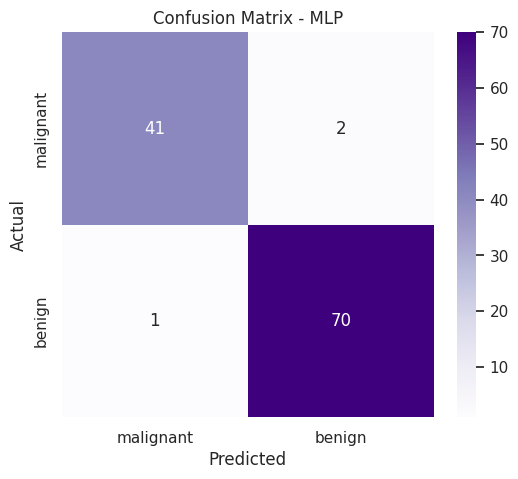

In [ ]:
# =========================================================
# MLP Classification Example - Breast Cancer Dataset
# =========================================================

# 1. Import libraries
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import seaborn as sns
import matplotlib.pyplot as plt

# =========================================================
# 2. Load dataset
# =========================================================

data = load_breast_cancer()

X = data.data
y = data.target

# =========================================================
# 3. Split dataset
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# =========================================================
# 4. Feature scaling
# IMPORTANT for neural networks
# =========================================================

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# =========================================================
# 5. Create MLP model
# =========================================================

mlp_model = MLPClassifier(
    hidden_layer_sizes=(100,),
    activation='relu',
    solver='adam',
    max_iter=1000,
    random_state=42
)

# =========================================================
# 6. Train model
# =========================================================

mlp_model.fit(X_train, y_train)

# =========================================================
# 7. Predictions
# =========================================================

y_pred = mlp_model.predict(X_test)

# =========================================================
# 8. Evaluation
# =========================================================

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

# =========================================================
# 9. Confusion Matrix
# =========================================================

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Purples", # cool, magma, BrBG, Pastel1, Purples, PuRd, RdPu
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

plt.title("Confusion Matrix - MLP")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

/tmp/ipykernel_635/60311437.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='Modelo', y='Exactitud', data=df_comparativa, palette='RdPu')


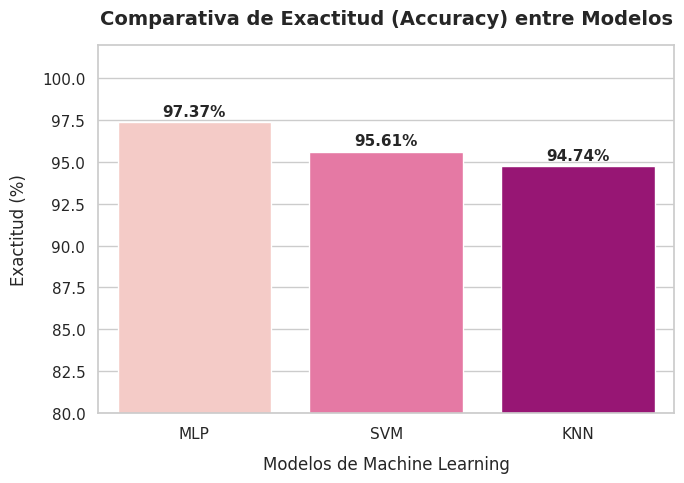

In [ ]:
# =========================================================
# 10. Comparativa Gráfica de Modelos
# =========================================================
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

# 1. Calculamos la exactitud (Accuracy) usando los modelos que ya están en memoria
acc_knn = accuracy_score(y_test, knn.predict(X_test))
acc_svm = accuracy_score(y_test, svm_model.predict(X_test))
acc_mlp = accuracy_score(y_test, mlp_model.predict(X_test))

# 2. Creamos un DataFrame con los resultados para manipularlos fácilmente
data_resultados = {
    'Modelo': ['KNN', 'SVM', 'MLP'],
    'Exactitud': [acc_knn * 100, acc_svm * 100, acc_mlp * 100] # Convertido a porcentaje
}
df_comparativa = pd.DataFrame(data_resultados)

# 3. Ordenamos los datos de mayor a menor exactitud
df_comparativa = df_comparativa.sort_values(by='Exactitud', ascending=False).reset_index(drop=True)

# 4. Configuramos el estilo estético del gráfico
sns.set_theme(style="whitegrid")
plt.figure(figsize=(7, 5))

# Creamos el gráfico de barras (usando una paleta degradada 'Blues_r')
ax = sns.barplot(x='Modelo', y='Exactitud', data=df_comparativa, palette='RdPu')
#YlGn_r, crest, RdPu_r, Purples_r, spring_r, magma_r

# 5. Personalizamos títulos y etiquetas
plt.title('Comparativa de Exactitud (Accuracy) entre Modelos', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Modelos de Machine Learning', fontsize=12, labelpad=10)
plt.ylabel('Exactitud (%)', fontsize=12, labelpad=10)

# Ajustamos el límite del eje Y para apreciar mejor las pequeñas diferencias
plt.ylim(80, 102)

# 6. Añadimos las etiquetas de texto con el porcentaje exacto arriba de cada barra
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}%",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 8),
                textcoords='offset points',
                fontsize=11, fontweight='bold')

# Mostramos el gráfico en pantalla
plt.tight_layout()
plt.show()



##El Objetivo Final: Capacidad de Generalización
Es la meta real de todo modelo: poder realizar predicciones exactas al enfrentarse a datos nuevos que jamás vio durante su entrenamiento.

###El puente lógico:

* Inducción (Entrenamiento): El modelo va de casos particulares (tus datos) para construir una regla general (la función de hipótesis).

* Deducción (Generalización): El modelo aplica esa regla general aprendida para resolver nuevos casos particulares en el mundo real.

##El Balance entre Subajuste y Sobreajuste
Para garantizar la generalización, el modelo debe evitar dos extremos:

* Subajuste (Underfitting): El modelo es demasiado simple. No aprende el patrón ni en el entrenamiento. Error alto en todo.

* Sobreajuste (Overfitting): El modelo se memoriza los datos de entrenamiento por exceso de complejidad. Tiene 100% de éxito entrenando, pero falla al generalizar con datos nuevos.

* Solución práctica: Dividir los datos con train_test_split (ej. 80% train / 20% test) para evaluar el modelo con datos "ciegos".


##Las Dos Grandes Ramas: Clasificación vs. Regresión

Dependen exclusivamente del tipo de variable que se quiere predecir ($y$):

Clasificación (Salida Categórica / Discreta): Predice etiquetas o clases finitas.

Binaria: Dos opciones (ej. Benigno/Maligno).Multiclase: Tres o más opciones (ej. Gato/Perro/Pájaro).

Regresión (Salida Continua / Numérica): Predice un número real e infinito (ej. El precio exacto de una casa o milisegundos de respuesta).



1. K-Nearest Neighbors (KNN) — El enfoque por vecindad
¿Cómo toma la decisión?: Es un modelo perezoso e intuitivo. No crea una ecuación matemática; simplemente guarda tus datos de entrenamiento. Cuando llega un paciente nuevo, mide la distancia geométrica en el mapa y mira a los 5 vecinos más cercanos (n_neighbors=5). Si la mayoría son benignos, dice que es benigno.

- Ventaja: Muy fácil de entender y rápido para añadir datos nuevos.

- Desventaja: Si tu base de datos se vuelve gigantesca (millones de registros), se vuelve extremadamente lento porque tiene que calcular la distancia de cada paciente nuevo contra todos los que ya tiene guardados.

2. Support Vector Machine (SVM) — El enfoque por fronteras claras
¿Cómo toma la decisión?: Es un modelo geométrico estricto. Busca trazar la mejor línea o "hiperplano" matemática para separar de manera perfecta los tumores malignos de los benignos. No le importan todos los datos; solo se concentra en los pacientes que quedaron justo en la frontera (los vectores de soporte) y maximiza el espacio libre (margen) entre ellos para no equivocarse al generalizar.

- Ventaja: Es increíblemente eficiente con datos de muchas dimensiones (como tus 30 características físicas del tumor) y muy estable.

- Desventaja: Si los datos están muy mezclados entre sí (ruido), le cuesta mucho trabajo encontrar una separación limpia.

3. Multi-Layer Perceptron (MLP / Redes Neuronales) — El enfoque por conexiones complejas
¿Cómo toma la decisión?: Imita la estructura del cerebro. Pasa las 30 características del tumor a través de una capa de 100 neuronas ocultas (hidden_layer_sizes=(100,)). Cada neurona procesa una pequeña combinación matemática mediante funciones de activación (relu) y se conecta con otras. Mediante el Backpropagation, ajusta los pesos de estas conexiones miles de veces hasta reducir el error al mínimo.

- Ventaja: Es el más poderoso de los tres. Puede aprender patrones y curvas extremadamente complejas que una línea recta de SVM o las distancias de KNN jamás detectarían (por eso te dio la exactitud más alta, cerca del 97.37%).

- Desventaja: Es una "caja negra"; es muy difícil explicar exactamente por qué una neurona interna tomó una decisión. Además, requiere mucho más poder de cómputo y tiempo para entrenar, y tiene un riesgo alto de caer en Overfitting si el dataset es pequeño.

##Resumen rápido:
- KNN clasifica comparando por cercanía con los vecinos.

- SVM clasifica trazando la mejor línea de división geométrica.

- MLP clasifica procesando la información a través de una red de neuronas interconectadas.